<center><h1>Slim_Alec_HW2</h1></center>
<br>
<br>

Name: Alec Slim
<br>
Github Username: alecwslim
<br>
USC ID: 

## 1. Combined Cycle Power Plant Data Set

### (a) Download Data

Package imports

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error


Get the Cycle Power Plant Data Set

In [2]:

df = pd.read_excel("../data/Folds5x2_pp.xlsx")
df

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90
...,...,...,...,...,...
9563,16.65,49.69,1014.01,91.00,460.03
9564,13.19,39.18,1023.67,66.78,469.62
9565,31.32,74.33,1012.92,36.48,429.57
9566,24.48,69.45,1013.86,62.39,435.74


### (b) Exploring the data

#### i. rows and columns

In [3]:
print(f"Rows: {df.shape[0]}\nColumns: {df.shape[1]}")

Rows: 9568
Columns: 5


#### ii. pairwise scatterplots of all the varianbles

Text(0.5, 1, 'Pairwise Scatterplot of all Variables')

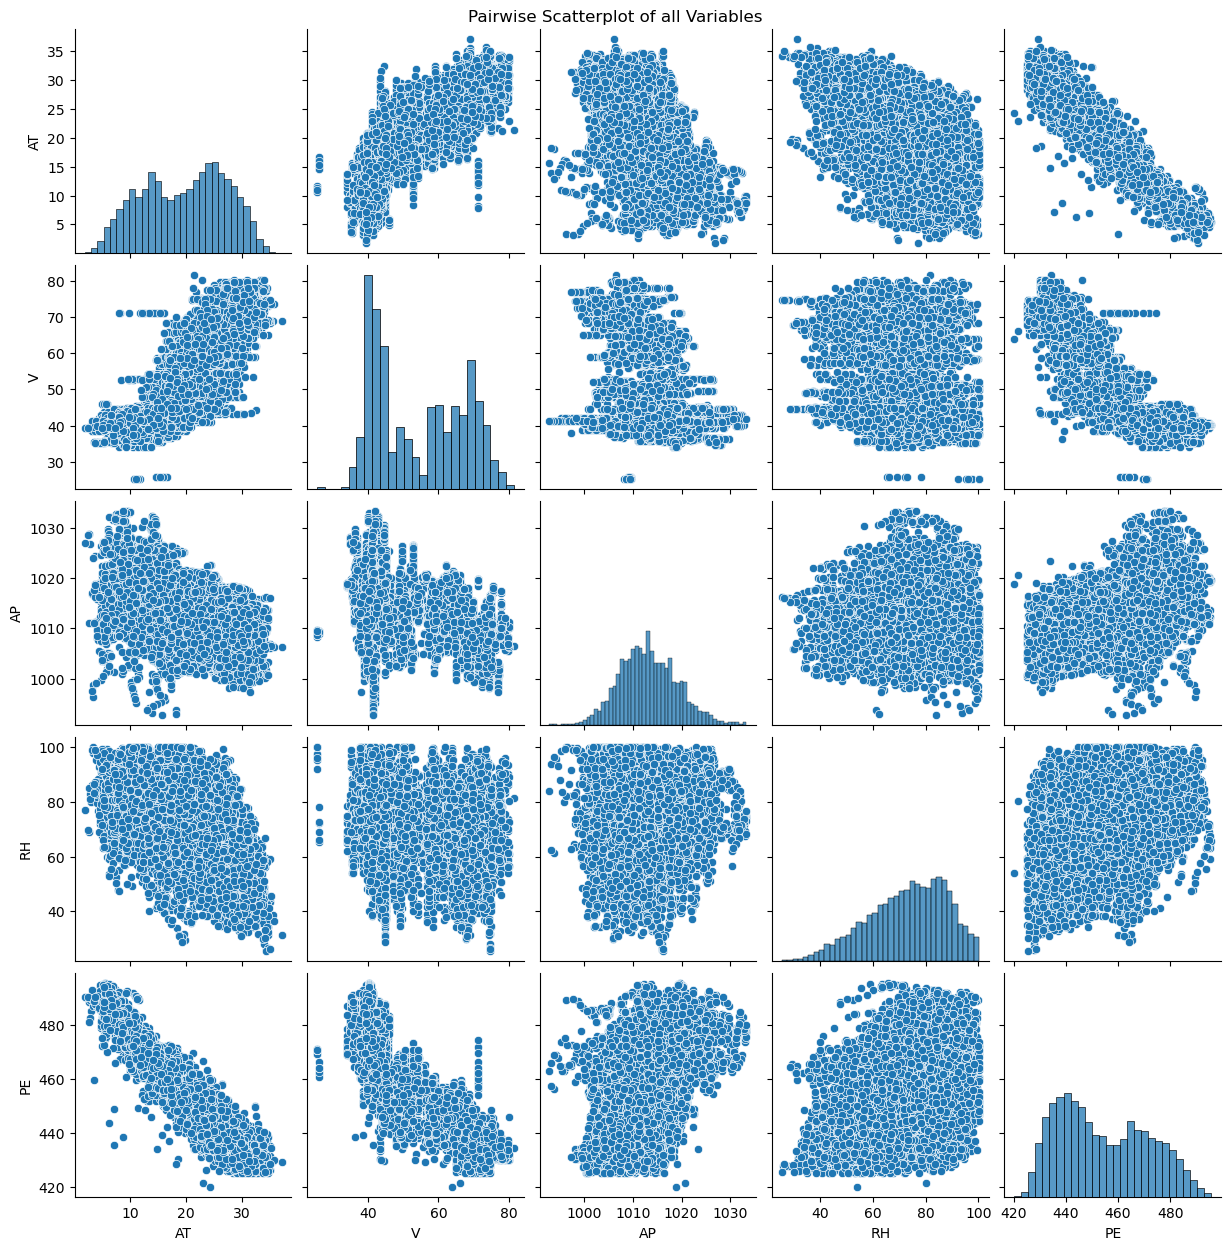

In [4]:
plot = sns.pairplot(df)
plot.figure.suptitle("Pairwise Scatterplot of all Variables", y=1)

AT and PE seem to have a very strong negative correlation where as AT increases PE decreases. Based on visuals alone they have the strongest correlation. V and AT along with V and PE have a visible correlation with some data points that do not follow the correlation path. 

#### iii. mean, the median, range, first and third quartiles, and interquartile ranges

In [5]:
stats_df = pd.DataFrame({
    "mean": df.mean(),
    "median": df.median(),
    "range": df.max() - df.min(),
    "1st quartile": df.quantile(0.25),
    "3rd quartile": df.quantile(0.75)
})
stats_df["Interquantile Range"] = stats_df["1st quartile"] - stats_df["3rd quartile"]
stats_df

,mean,median,range,1st quartile,3rd quartile,Interquantile Range
AT,19.651231,20.345,35.30,13.5100,25.72,-12.2100
V,54.305804,52.080,56.20,41.7400,66.54,-24.8000
AP,1013.259078,1012.940,40.41,1009.1000,1017.26,-8.1600
RH,73.308978,74.975,74.60,63.3275,84.83,-21.5025
PE,454.365009,451.550,75.50,439.7500,468.43,-28.6800


### (c) Simple Linear Regression

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.899
Model:                            OLS   Adj. R-squared:                  0.899
Method:                 Least Squares   F-statistic:                 8.510e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:34   Log-Likelihood:                -29756.
No. Observations:                9568   AIC:                         5.952e+04
Df Residuals:                    9566   BIC:                         5.953e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        497.0341      0.156   3177.280      0.0

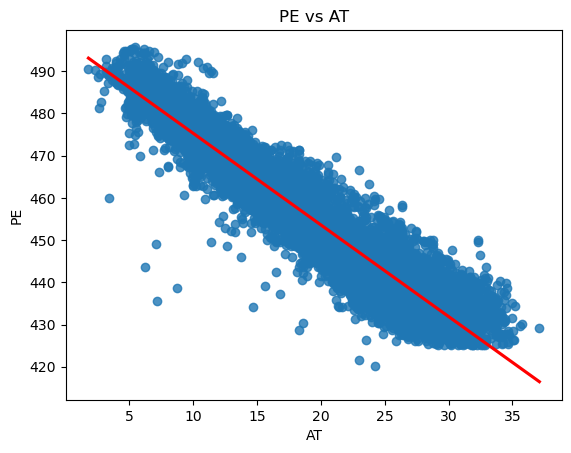

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.757
Model:                            OLS   Adj. R-squared:                  0.756
Method:                 Least Squares   F-statistic:                 2.972e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -33963.
No. Observations:                9568   AIC:                         6.793e+04
Df Residuals:                    9566   BIC:                         6.794e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        517.8015      0.378   1370.218      0.0

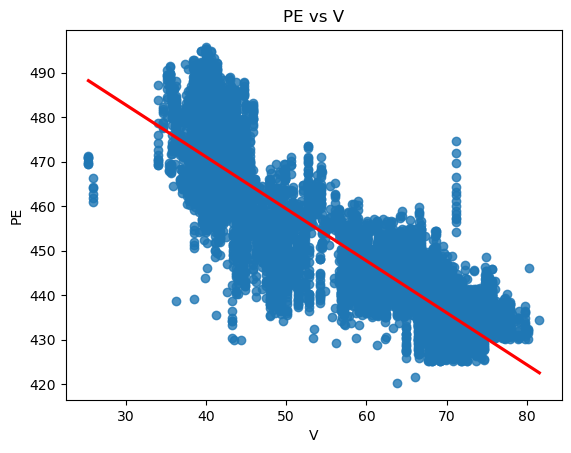

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.269
Model:                            OLS   Adj. R-squared:                  0.269
Method:                 Least Squares   F-statistic:                     3516.
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -39224.
No. Observations:                9568   AIC:                         7.845e+04
Df Residuals:                    9566   BIC:                         7.847e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const      -1055.2610     25.459    -41.449      0.0

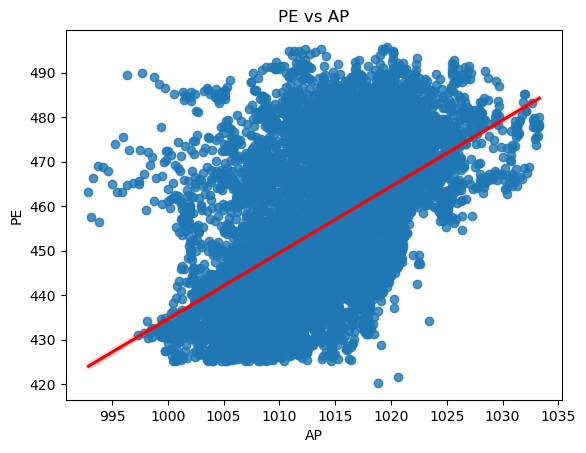

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.152
Model:                            OLS   Adj. R-squared:                  0.152
Method:                 Least Squares   F-statistic:                     1714.
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -39933.
No. Observations:                9568   AIC:                         7.987e+04
Df Residuals:                    9566   BIC:                         7.988e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        420.9618      0.823    511.676      0.0

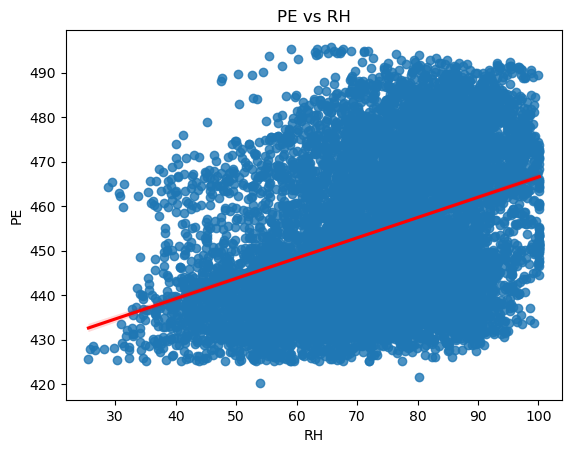

In [6]:
simple_coef = []
pred_df = df.drop("PE", axis=1)
for pred in pred_df.columns.tolist():
    X = sm.add_constant(df[[pred]])
    y = df["PE"]
    mdl = sm.OLS(y,X).fit()
    simple_coef.append(mdl.params[pred])
    
    print(mdl.summary())
    
    sns.regplot(data=df, x=pred, y=y, line_kws={"color": "red"})
    plt.title(f"PE vs {pred}")
    plt.show()

Since all variables had a P value of less than 0.05 they all have a statistically siginificant association with PE. There are outliers for the V variable near both extremes that I would like to remove from the dataset as well as some outiliers for AT that do not follow the regression line trend. AP is also has the largest postive coeffiecnt.

### (d) Multiple Regression

In [7]:
X = sm.add_constant(pred_df)
y = df["PE"]

mult_reg = sm.OLS(y,X).fit()
print(mult_reg.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 3.114e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -28088.
No. Observations:                9568   AIC:                         5.619e+04
Df Residuals:                    9563   BIC:                         5.622e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        454.6093      9.749     46.634      0.0

The results show that all variables should reject the null hypothesis since the P values are > 0.05. AT has the most signficant coeficiant of -1.9775 meaning it contributes the most to the prediction in this model.

### (e) 1c Compare to 1d

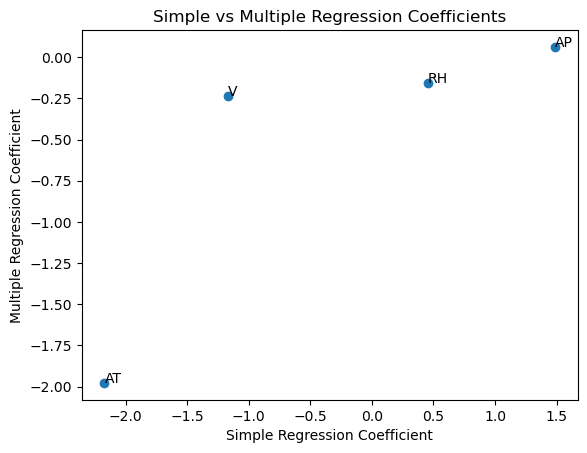

In [8]:
predictors = pred_df.columns.tolist()
mult_coef = [mult_reg.params[pred] for pred in predictors]
plt.scatter(simple_coef, mult_coef)

for i, pred in enumerate(predictors):
    plt.annotate(
        pred,
        (simple_coef[i], mult_coef[i])
    )

plt.xlabel("Simple Regression Coefficient")
plt.ylabel("Multiple Regression Coefficient")
plt.title("Simple vs Multiple Regression Coefficients")
plt.show()

The variable coefficents were not consistent across the simple and multiple regression apart from AT which remained around -2.0 in both models. V, RH, and AP had a narrow distribution in the multiple model but was spread out in the simple regression. 

### (f) Nonlinear Association

In [9]:
for predictor in predictors:
    X = df[predictor]
    x_nonlin = pd.DataFrame({
        predictor: X,
        f"{predictor}^2": X**2,
        f"{predictor}^3": X**3
    })
    
    x_nonlin = sm.add_constant(x_nonlin)
    model = sm.OLS(df["PE"], x_nonlin).fit()
    print(model.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.912
Model:                            OLS   Adj. R-squared:                  0.912
Method:                 Least Squares   F-statistic:                 3.299e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -29101.
No. Observations:                9568   AIC:                         5.821e+04
Df Residuals:                    9564   BIC:                         5.824e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        492.7281      0.673    732.248      0.0

All variables show evidence of nonlinearity with most having X^2 and X^3 values > 0.05. V had a X^2 P-value of 0.768 and a X^3 P-value of 0.014 which despite the value of X^2 proves there is still evidence of a nonlinear association.

### (g) Interactions of Predictors

In [10]:
interactions = smf.ols(
    "PE ~ AT * V + AT * AP + AT * RH + V * AP + V * RH + AP * RH",
    data=df
).fit()

print(interactions.summary())

                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.936
Model:                            OLS   Adj. R-squared:                  0.936
Method:                 Least Squares   F-statistic:                 1.405e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -27548.
No. Observations:                9568   AIC:                         5.512e+04
Df Residuals:                    9557   BIC:                         5.520e+04
Df Model:                          10                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    685.7825     78.640      8.721      0.0

ATxV, ATxAP, ATxRH, VxAP, APxRH are all statistically significant.

### (h) Improvement

In [11]:
train_df, test_df = train_test_split(df, test_size=0.30, random_state=42)

basic = smf.ols(
    "PE ~ AT + V + AP + RH",
    data=train_df
).fit()

print(basic.summary())

full_model = smf.ols(
    """
    PE ~ AT + V + AP + RH
       + I(AT**2) + I(V**2) + I(AP**2) + I(RH**2)
       + AT:V + AT:AP + AT:RH
       + V:AP + V:RH + AP:RH
    """,
    data=train_df
).fit()

print(full_model.summary())

reduced = smf.ols(
    """
    PE ~ AT + V + AP + RH
       + I(AT**2) + I(AP**2) + I(RH**2)
       + AT:V + AT:RH + AP:RH
    """,
    data=train_df
).fit()

print(reduced.summary())


basic_pred_train = basic.predict(train_df)
basic_pred_test = basic.predict(test_df)

basic_train_mse = mean_squared_error(train_df["PE"], basic_pred_train)
basic_test_mse = mean_squared_error(test_df["PE"], basic_pred_test)



reduce_pred_train = reduced.predict(train_df)
reduce_pred_test = reduced.predict(test_df)

reduce_train_mse = mean_squared_error(train_df["PE"], reduce_pred_train)
reduce_test_mse = mean_squared_error(test_df["PE"], reduce_pred_test)

print(f'Basic Training MSE: {basic_train_mse}')
print(f'Basic Test MSE: {basic_test_mse}')
print(f'Reduced Training MSE: {reduce_train_mse}')
print(f'Reduced Test MSE: {basic_test_mse}')


                            OLS Regression Results                            
Dep. Variable:                     PE   R-squared:                       0.929
Model:                            OLS   Adj. R-squared:                  0.929
Method:                 Least Squares   F-statistic:                 2.194e+04
Date:                Mon, 28 Sep 2026   Prob (F-statistic):               0.00
Time:                        21:11:35   Log-Likelihood:                -19630.
No. Observations:                6697   AIC:                         3.927e+04
Df Residuals:                    6692   BIC:                         3.930e+04
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept    467.8414     11.502     40.673      0.0

Yes by removing the insignificant features that do not correlate to any significant features, I was able to lower the testing MSE from 21.24 in the basic model to 17.92 in the reduced model.

### (i) KNN

Best k: 5
Best test MSE: 15.726819842563568
Best normalized k: 4
Best normalized test MSE: 14.305669422675024


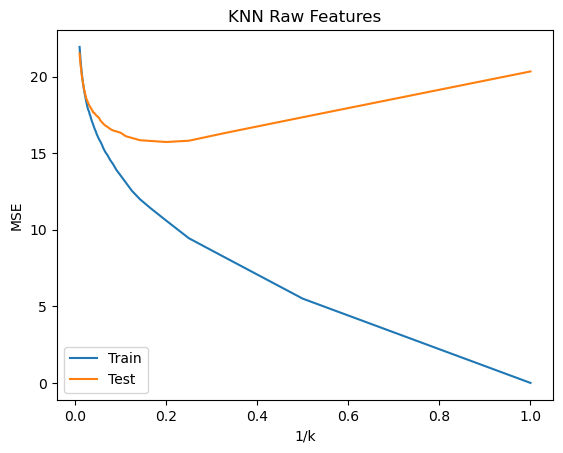

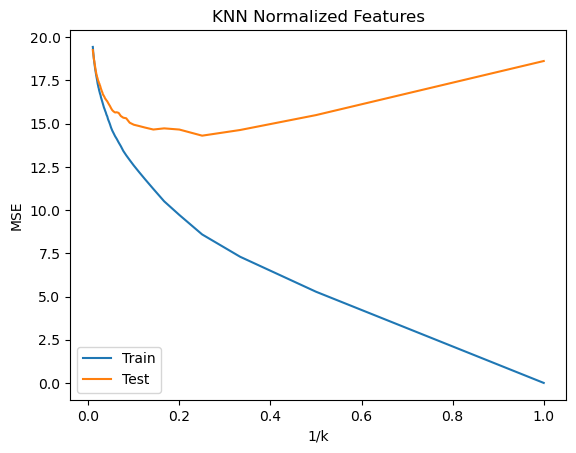

In [12]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.30,random_state=42)
train_err = []
test_err = []

k_val = range(1,101)

for k in k_val:
    knn = KNeighborsRegressor(n_neighbors=k)
    
    knn.fit(X_train, y_train)
    train_pred = knn.predict(X_train)
    test_pred = knn.predict(X_test)
    train_err.append(mean_squared_error(y_train, train_pred))
    test_err.append(mean_squared_error(y_test, test_pred))
    
best = np.argmin(test_err)

best_k =list(k_val)[best]    
print(f"Best k: {best_k}")
print(f"Best test MSE: {test_err[best]}")

scaler = StandardScaler()
scaled_X_train = scaler.fit_transform(X_train)
scaled_X_test = scaler.transform(X_test)

norm_train_errors = []
norm_test_errors = []

for k in k_val:
    knn = KNeighborsRegressor(n_neighbors=k)

    knn.fit(scaled_X_train, y_train)

    train_pred = knn.predict(scaled_X_train)
    test_pred = knn.predict(scaled_X_test)

    norm_train_errors.append(mean_squared_error(y_train, train_pred))

    norm_test_errors.append(mean_squared_error(y_test, test_pred)) 
     
best_norm_index = np.argmin(norm_test_errors)
best_norm_k = list(k_val)[best_norm_index]
print("Best normalized k:", best_norm_k)
print("Best normalized test MSE:", norm_test_errors[best_norm_index])


inverse_k = [1/k for k in k_val]
plt.plot(inverse_k, train_err, label="Train")
plt.plot(inverse_k, test_err, label="Test")
plt.xlabel("1/k")
plt.ylabel("MSE")
plt.title("KNN Raw Features")
plt.legend()
plt.show()

plt.plot(inverse_k, norm_train_errors, label="Train")
plt.plot(inverse_k, norm_test_errors, label="Test")
plt.xlabel("1/k")
plt.ylabel("MSE")
plt.title("KNN Normalized Features")
plt.legend()
plt.show()

### (j ) Compare KNN and Linear

In [13]:
print("Basic Linear Regression:", basic_test_mse)
print("Improved Linear Regression:", reduce_test_mse)
print("Best Raw KNN:", min(test_err))
print("Best Normalized KNN:", min(norm_test_errors))

Basic Linear Regression: 21.239856938225444
Improved Linear Regression: 18.694346190806307
Best Raw KNN: 15.726819842563568
Best Normalized KNN: 14.305669422675024


Overall KNN had a better MSE as compared to both linear regression models. The normalized KNN had the lowest MSE meaning it is the best option for this dataset out of the available options.

## 2. ISLR: 2.4.1

### (a) The sample size n is extremely large, and the number of predictors p is small.

A Flexible method is better in this situation because there is a lot of data in relation to the number of predictors. The flexible method would be able to learn meaningful relationships without overfitting.

### (b) The number of predictors p is extremely large, and the number of observations n is small.

A flexible method is bad in this situation becasue it will cause overfitting due to having so many observations with not a lot of data. This means it will not reflect real world situations well at all.

### (c) The relationship between the predictors and response is highly non-linear.

A flexible method would be better in this situation. Models like linear regression uses shape to make strong assumptions about the data and with a non-linear relationship it would cause overfitting. This is not a problem when it comes to a flexible approach.

### (d) The variance of the error terms, i.e. $σ^2$ = Var(ε), is extremely high.

A flexible model would be worse in this situation. when \(\sigma^2\) is high there is a lot of noise in the data meaning that the flexible model would fit to that noise over the general relationship.

## 3. ISLR: 2.4.7

### (a) Compute the Euclidean distance between each observation and the test point, X1 = X2 = X3 = 0.

In [14]:
X = np.array([
    [0, 3, 0],
    [2, 0, 0],
    [0, 1, 3],
    [0, 1, 2],
    [-1, 0, 1],
    [1, 1, 1]])

point = np.array([0, 0, 0])
for i, observation in enumerate(X):
    distance = np.linalg.norm(observation - point)
    print(f"Observation {i + 1}: {distance}")

Observation 1: 3.0
Observation 2: 2.0
Observation 3: 3.1622776601683795
Observation 4: 2.23606797749979
Observation 5: 1.4142135623730951
Observation 6: 1.7320508075688772


### (b) What is our prediction with K = 1? Why?

Green because observation 5 has the closest distance to the prediction point and because k=1 only the nearest point is counted which is labeled as green. 

### (c) What is our prediction with K = 3? Why?

Red becasue the 3 nearest observations to the point were 5, 6, and 2 which came out to 2 red and 1 green. Since red was the majority, the prediction is red.

### (d) If the Bayes decision boundary in this problem is highly non-linear, then would we expect the best value for K to be large or small? Why?

The best value for K would be small becasue we would want the model to be flexible in this situation and to do that it would need a smaller K value.